In [4]:
# # Fetch Variables Preparation - Complete Workflow
# This notebook calculates Euclidean distance and direction to the nearest ridge for fetch analysis.
# 
# **Workflow:**
# 1. DEM smoothing to identify regional topography
# 2. Local relief calculation (DEM - smoothed DEM)
# 3. Flow accumulation analysis to identify ridges vs valleys
# 4. Ridge identification (relief > 500m/1000m AND low flow accumulation)
# 5. Distance and direction calculation to nearest ridge


In [5]:
import os
import gc
import numpy as np
import pandas as pd
import geopandas as gpd
import rioxarray as rxr
import xarray as xr
import rasterio
import matplotlib.pyplot as plt
import whitebox
from scipy.ndimage import uniform_filter, distance_transform_edt

# Initialize whitebox
wbt = whitebox.WhiteboxTools()

# Set project paths
input_dem_path = r"C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Datasets\DEM_1km\DEM_90m_elevation_geemap.tif"
out_dir = r"C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\Preprocessing"
final_dir = r"C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch"

# Create output directories
os.makedirs(out_dir, exist_ok=True)
os.makedirs(final_dir, exist_ok=True)

# Set smoothing window size (50km radius ≈ 556 pixels at 90m resolution)
window_size = 555

print(f"Output directory: {out_dir}")
print(f"Final directory: {final_dir}")
print(f"Smoothing window size: {window_size} pixels")


Output directory: C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\Preprocessing
Final directory: C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch
Smoothing window size: 555 pixels


Loading DEM...
DEM shape: (1, 9979, 17286)
DEM CRS: EPSG:4326
DEM resolution: (0.0008084837557075694, -0.0008084837557075694)


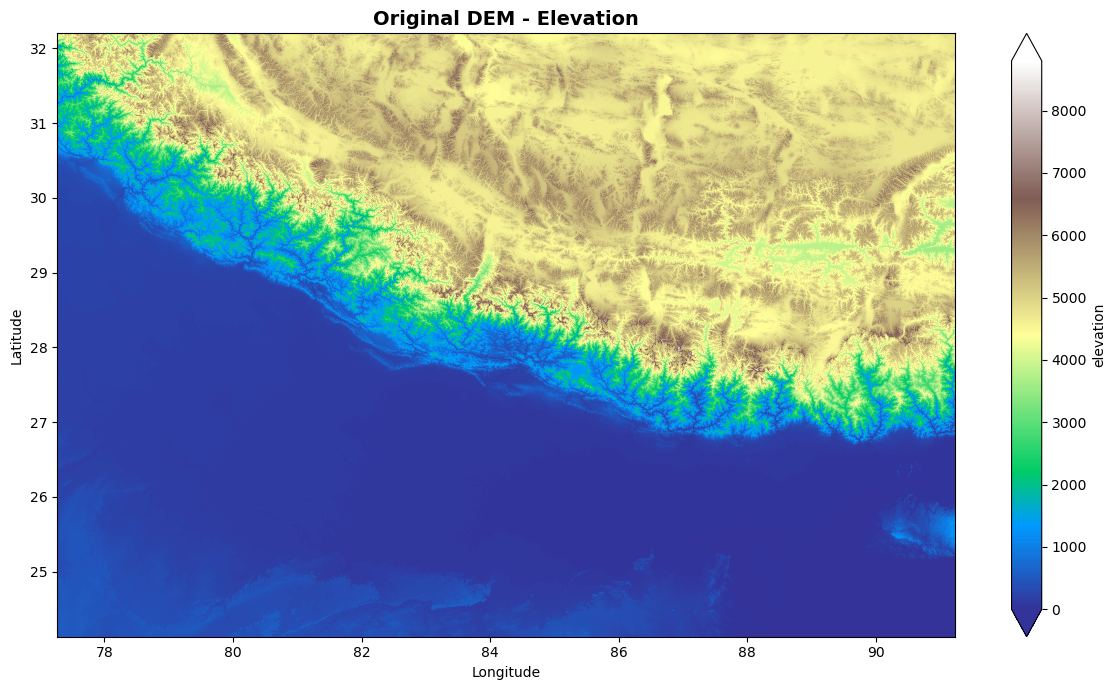

In [6]:
# ## Step 1: Load and Visualize Original DEM

# %%
print("Loading DEM...")
dem_rxr = rxr.open_rasterio(input_dem_path)
dem_rxr = dem_rxr.rio.write_crs("EPSG:4326")

print(f"DEM shape: {dem_rxr.shape}")
print(f"DEM CRS: {dem_rxr.rio.crs}")
print(f"DEM resolution: {dem_rxr.rio.resolution()}")

# Visualize original DEM
xr.set_options(keep_attrs=True, display_expand_data=False)

plt.figure(figsize=(12, 7))
dem_rxr.sel(band=1).plot.imshow(
    cmap='terrain',
    vmin=0,
    vmax=8800
)
plt.title("Original DEM - Elevation", fontsize=14, fontweight='bold')
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()


Smoothing DEM with uniform filter...
DEM smoothing complete.


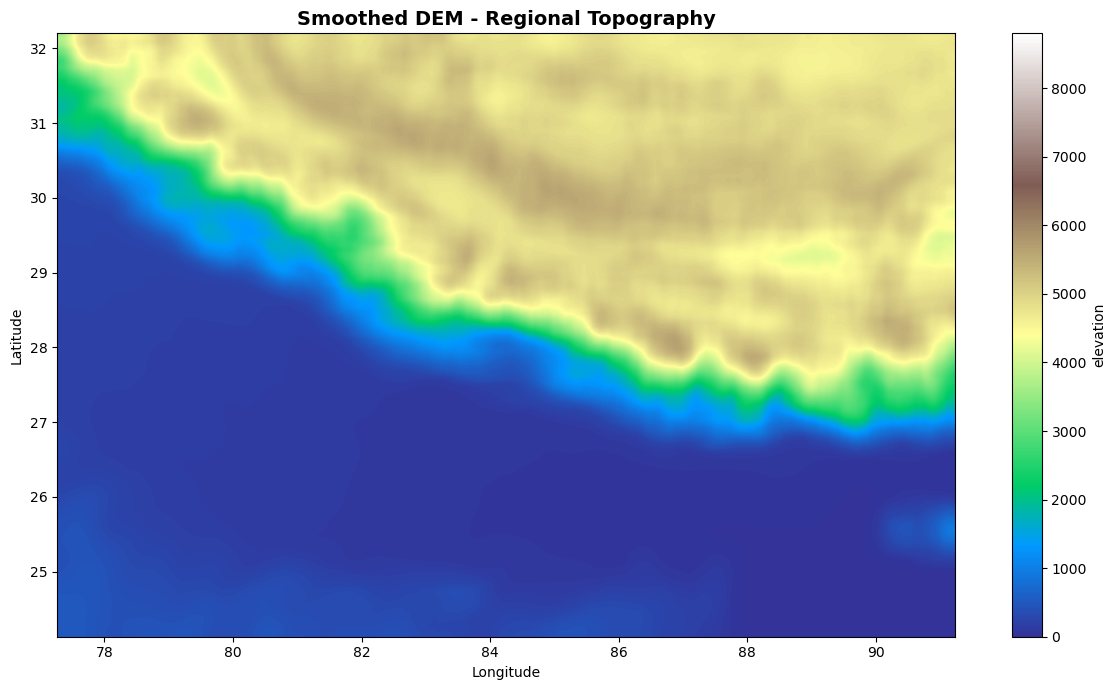

Smoothed DEM saved to C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\Preprocessing\dem_smoothed.tif


11924

In [7]:
# ## Step 2: DEM Smoothing (Regional Topography)

print("Smoothing DEM with uniform filter...")

# Convert to numpy and handle NaN values
dem_np = dem_rxr.to_numpy()
dem_np = np.nan_to_num(dem_np, nan=0.0)

# Apply uniform filter for regional smoothing
dem_smoothed = uniform_filter(dem_np.astype(np.float32), size=window_size, mode='reflect')

# Convert back to xarray with original coordinates
dem_smoothed_rxr = dem_rxr.copy(data=dem_smoothed)

print("DEM smoothing complete.")

# Visualize smoothed DEM
plt.figure(figsize=(12, 7))
dem_smoothed_rxr.sel(band=1).plot.imshow(
    cmap='terrain',
    vmin=0,
    vmax=8800
)
plt.title("Smoothed DEM - Regional Topography", fontsize=14, fontweight='bold')
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

# Save smoothed DEM
smoothed_dem_path = os.path.join(out_dir, "dem_smoothed.tif")
dem_smoothed_rxr.rio.to_raster(smoothed_dem_path)
print(f"Smoothed DEM saved to {smoothed_dem_path}")

# Clear memory
del dem_np, dem_smoothed
gc.collect()

Calculating local relief...
Local relief calculation complete.


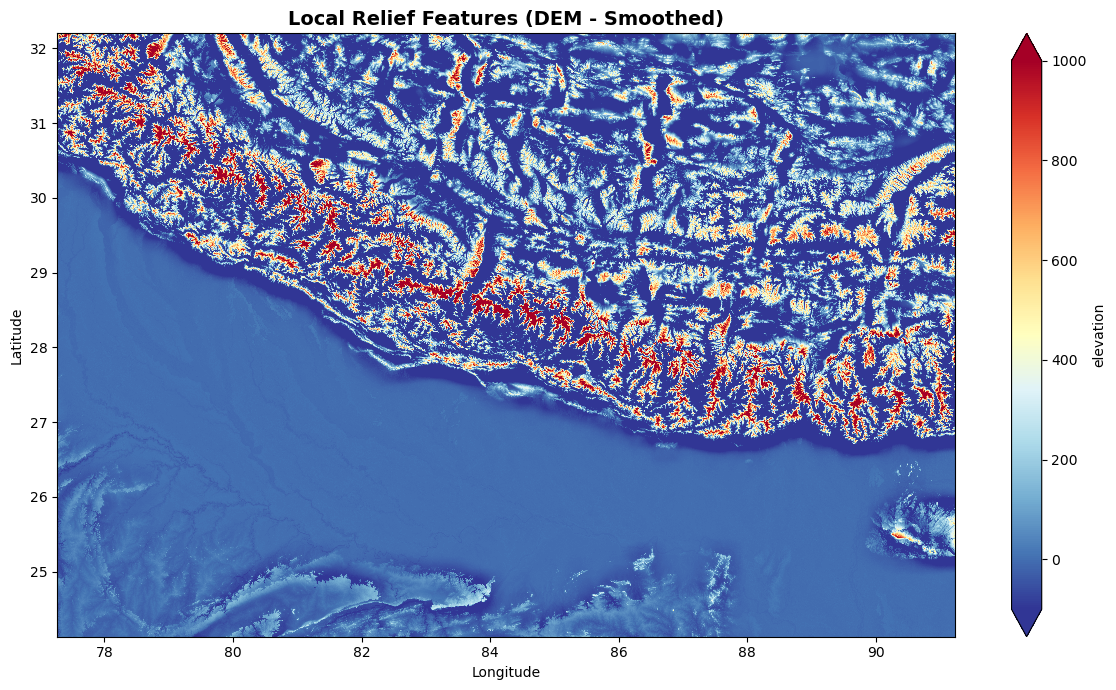

Local relief saved to C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\Preprocessing\local_relief.tif
DEM variables cleared from memory.


In [8]:
# ## Step 3: Local Relief Calculation

print("Calculating local relief...")

# Local relief = Original DEM - Smoothed DEM
local_relief_rxr = dem_rxr - dem_smoothed_rxr

print("Local relief calculation complete.")

# Visualize local relief
plt.figure(figsize=(12, 7))
local_relief_rxr.sel(band=1).plot.imshow(
    cmap='RdYlBu_r',
    vmin=-100,
    vmax=1000
)
plt.title("Local Relief Features (DEM - Smoothed)", fontsize=14, fontweight='bold')
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

# Save local relief
relief_path = os.path.join(out_dir, "local_relief.tif")
local_relief_rxr.rio.to_raster(relief_path)
print(f"Local relief saved to {relief_path}")

# Clear DEM variables from memory
del dem_rxr, dem_smoothed_rxr, local_relief_rxr
gc.collect()
print("DEM variables cleared from memory.")

In [9]:
# ## Step 4: Flow Accumulation Analysis (WhiteboxTools)

print("Running flow accumulation analysis...")

# Define output paths for flow accumulation workflow
out_dem_path = os.path.join(out_dir, "dem_filled.tif")
out_pntr_path = os.path.join(out_dir, "flow_pointer.tif")
out_accum_path = os.path.join(out_dir, "flow_accumulation.tif")

# Run full workflow (breach/fill + pointer + accumulation)
wbt.flow_accumulation_full_workflow(
    input_dem_path,
    out_dem_path,
    out_pntr_path,
    out_accum_path,
    out_type="Specific Contributing Area",
    log=False,
    clip=False,
    esri_pntr=False
)

print(f"Flow accumulation saved to {out_accum_path}")
print("Flow accumulation analysis complete.")

# Clear whitebox object
del wbt
gc.collect()

Running flow accumulation analysis...
.\whitebox_tools.exe --run="FlowAccumulationFullWorkflow" --dem='C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Datasets\DEM_1km\DEM_90m_elevation_geemap.tif' --out_dem='C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\Preprocessing\dem_filled.tif' --out_pntr='C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\Preprocessing\flow_pointer.tif' --out_accum='C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\Preprocessing\flow_accumulation.tif' --out_type=Specific Contributing Area -v --compress_rasters=False

*******************************************
* Welcome to FlowAccumulationFullWorkflow *
* Powered by WhiteboxTools                *
* www.whiteboxgeo.com                     *
*******************************************
Reading data...
Calculating aspect: 0%
Calculating aspect: 1%
Calculating aspect: 2%
Calculating aspect: 3%
Calculating aspect: 

0

Identifying ridges...
Reprojecting flow accumulation to match local relief CRS...
Local relief shape: (1, 9979, 17286)
Flow accumulation shape: (1, 9979, 17286)
Ridge identification complete.


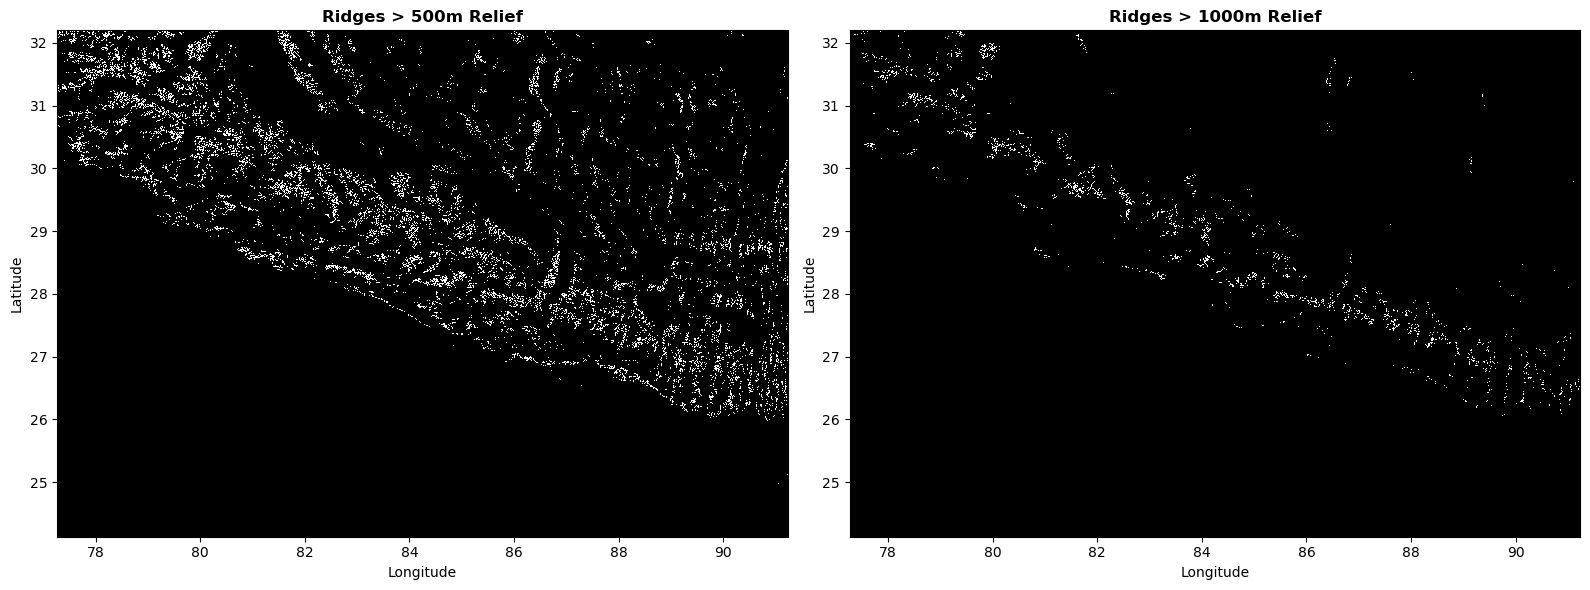

Ridge masks saved to C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\Preprocessing


106

In [10]:
# ## Step 5: Ridge Identification

print("Identifying ridges...")

# Load local relief and flow accumulation
local_relief_rxr = rxr.open_rasterio(relief_path)
flow_accum_rxr = rxr.open_rasterio(out_accum_path)

# Reproject flow accumulation to match local relief
print("Reprojecting flow accumulation to match local relief CRS...")
flow_accum_rxr = flow_accum_rxr.rio.reproject(local_relief_rxr.rio.crs)

print(f"Local relief shape: {local_relief_rxr.shape}")
print(f"Flow accumulation shape: {flow_accum_rxr.shape}")

# Identify ridges based on criteria:
# - Relief > 500m/1000m (indicates significant topographic prominence)
# - Flow accumulation <= 0.002 (indicates ridges, not valleys)

ridge_500m_rxr = xr.where(
    (local_relief_rxr > 500) & (flow_accum_rxr <= 0.002),
    1,
    0
).astype(np.uint8)

ridge_1000m_rxr = xr.where(
    (local_relief_rxr > 1000) & (flow_accum_rxr <= 0.002),
    1,
    0
).astype(np.uint8)

# Write CRS
ridge_500m_rxr = ridge_500m_rxr.rio.write_crs("EPSG:4326")
ridge_1000m_rxr = ridge_1000m_rxr.rio.write_crs("EPSG:4326")

print("Ridge identification complete.")

# Visualize ridges
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ridge_500m_rxr.sel(band=1).plot.imshow(
    ax=axes[0],
    cmap='Greys_r',
    add_colorbar=False
)
axes[0].set_title("Ridges > 500m Relief", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

ridge_1000m_rxr.sel(band=1).plot.imshow(
    ax=axes[1],
    cmap='Greys_r',
    add_colorbar=False
)
axes[1].set_title("Ridges > 1000m Relief", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

plt.tight_layout()
plt.show()

# Save ridge masks
ridge_500m_path = os.path.join(out_dir, "ridge_500m.tif")
ridge_1000m_path = os.path.join(out_dir, "ridge_1000m.tif")

ridge_500m_rxr.rio.to_raster(ridge_500m_path)
ridge_1000m_rxr.rio.to_raster(ridge_1000m_path)

print(f"Ridge masks saved to {out_dir}")

# Clear intermediate variables
del local_relief_rxr, flow_accum_rxr
gc.collect()


Calculating Euclidean distance and direction to ridges > 500m...
Distance and direction calculation complete (500m).


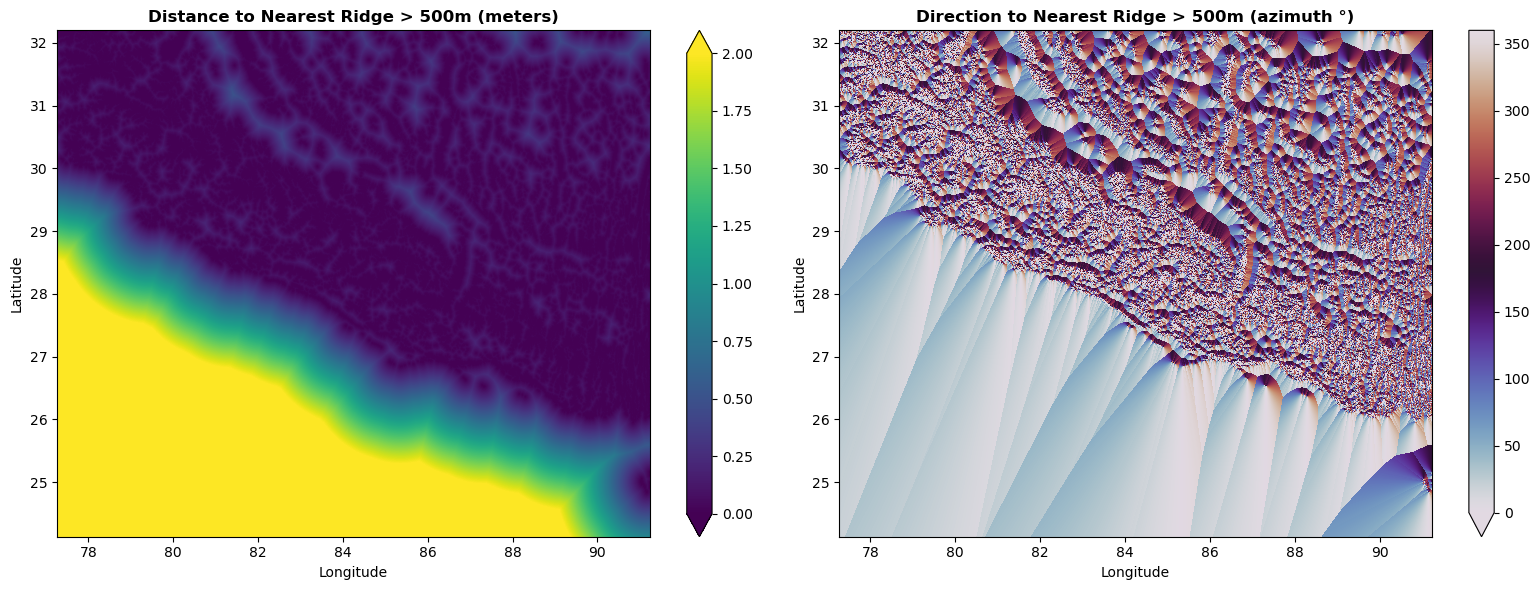

Fetch distance (500m) saved to C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\fetch_dist_500m.tif
Fetch direction (500m) saved to C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\fetch_dir_500m.tif


6558

In [11]:
# ## Step 6: Calculate Distance and Direction to Ridges (500m)

# %%
print("Calculating Euclidean distance and direction to ridges > 500m...")

# Get ridge mask values
ridge_mask_500 = ridge_500m_rxr.values[0]

# Distance Transform:
# EDT calculates distance from background (0) to nearest ridge (1)
# So we pass (ridge_mask == 0) to find distance FROM non-ridge TO ridge
dist_pix_500, indices_500 = distance_transform_edt(
    ridge_mask_500 == 0, 
    return_indices=True
)

# Convert pixel distance to meters
pixel_size = ridge_500m_rxr.rio.resolution()[0]
dist_500_m = dist_pix_500 * abs(pixel_size)

# Calculate azimuth (direction) to nearest ridge
rows_500, cols_500 = np.indices(ridge_mask_500.shape)
delta_y_500 = indices_500[0] - rows_500
delta_x_500 = indices_500[1] - cols_500

# Calculate azimuth (0° = North, 90° = East, 180° = South, 270° = West)
azimuth_rad_500 = np.arctan2(delta_x_500, -delta_y_500)
azimuth_deg_500 = np.degrees(azimuth_rad_500)
azimuth_deg_500 = (azimuth_deg_500 + 360) % 360

# Mask out ridge pixels (set to nodata value)
is_ridge_500 = (ridge_mask_500 == 1)
dist_500_m[is_ridge_500] = -0.1
azimuth_deg_500[is_ridge_500] = -0.1

# Expand dimensions to match original shape
dist_500_m = np.expand_dims(dist_500_m, axis=0)
azimuth_deg_500 = np.expand_dims(azimuth_deg_500, axis=0)

# Create xarray objects
dist_500_rxr = ridge_500m_rxr.copy(data=dist_500_m)
azimuth_500_rxr = ridge_500m_rxr.copy(data=azimuth_deg_500)

print("Distance and direction calculation complete (500m).")

# Visualize results
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

dist_500_rxr.sel(band=1).plot.imshow(
    ax=axes[0],
    cmap='viridis',
    vmin=0,
    vmax= 2
)
axes[0].set_title("Distance to Nearest Ridge > 500m (meters)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

azimuth_500_rxr.sel(band=1).plot.imshow(
    ax=axes[1],
    cmap='twilight',
    vmin=0,
    vmax=360
)
axes[1].set_title("Direction to Nearest Ridge > 500m (azimuth °)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

plt.tight_layout()
plt.show()

# Save final outputs
dist_500_path = os.path.join(final_dir, "fetch_dist_500m.tif")
azimuth_500_path = os.path.join(final_dir, "fetch_dir_500m.tif")

dist_500_rxr.rio.to_raster(dist_500_path)
azimuth_500_rxr.rio.to_raster(azimuth_500_path)

print(f"Fetch distance (500m) saved to {dist_500_path}")
print(f"Fetch direction (500m) saved to {azimuth_500_path}")

# Clear variables
del ridge_mask_500, dist_pix_500, indices_500, dist_500_m
del rows_500, cols_500, delta_y_500, delta_x_500
del azimuth_rad_500, azimuth_deg_500, is_ridge_500
del dist_500_rxr, azimuth_500_rxr
gc.collect()

Calculating Euclidean distance and direction to ridges > 1000m...
Distance and direction calculation complete (1000m).


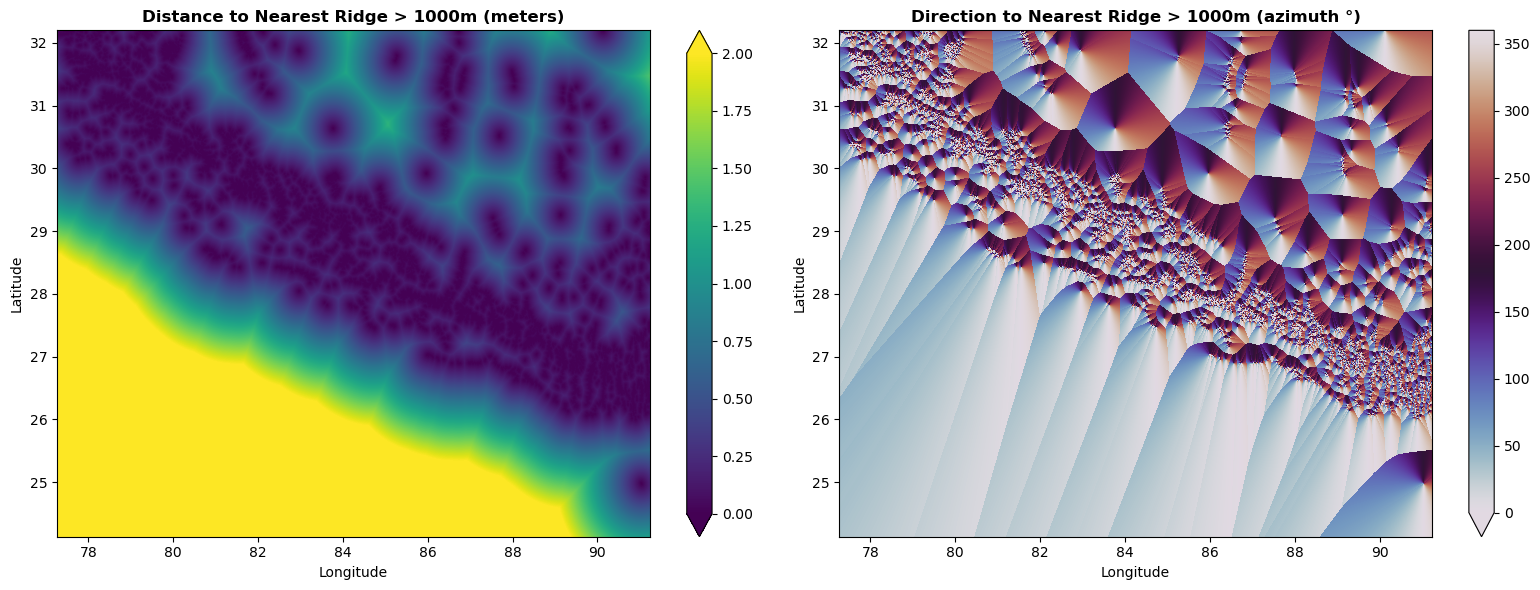

Fetch distance (1000m) saved to C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\fetch_dist_1000m.tif
Fetch direction (1000m) saved to C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\fetch_dir_1000m.tif


11622

In [12]:
# ## Step 7: Calculate Distance and Direction to Ridges (1000m)

print("Calculating Euclidean distance and direction to ridges > 1000m...")

# Get ridge mask values
ridge_mask_1000 = ridge_1000m_rxr.values[0]

# Distance Transform
dist_pix_1000, indices_1000 = distance_transform_edt(
    ridge_mask_1000 == 0, 
    return_indices=True
)

# Convert to meters
pixel_size = ridge_1000m_rxr.rio.resolution()[0]
dist_1000_m = dist_pix_1000 * abs(pixel_size)

# Calculate azimuth
rows_1000, cols_1000 = np.indices(ridge_mask_1000.shape)
delta_y_1000 = indices_1000[0] - rows_1000
delta_x_1000 = indices_1000[1] - cols_1000

azimuth_rad_1000 = np.arctan2(delta_x_1000, -delta_y_1000)
azimuth_deg_1000 = np.degrees(azimuth_rad_1000)
azimuth_deg_1000 = (azimuth_deg_1000 + 360) % 360

# Mask ridge pixels
is_ridge_1000 = (ridge_mask_1000 == 1)
dist_1000_m[is_ridge_1000] = -9999
azimuth_deg_1000[is_ridge_1000] = -9999

# Expand dimensions
dist_1000_m = np.expand_dims(dist_1000_m, axis=0)
azimuth_deg_1000 = np.expand_dims(azimuth_deg_1000, axis=0)

# Create xarray objects
dist_1000_rxr = ridge_1000m_rxr.copy(data=dist_1000_m)
azimuth_1000_rxr = ridge_1000m_rxr.copy(data=azimuth_deg_1000)

print("Distance and direction calculation complete (1000m).")

# Visualize results
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

dist_1000_rxr.sel(band=1).plot.imshow(
    ax=axes[0],
    cmap='viridis',
    vmin=0,
    vmax=2
)
axes[0].set_title("Distance to Nearest Ridge > 1000m (meters)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

azimuth_1000_rxr.sel(band=1).plot.imshow(
    ax=axes[1],
    cmap='twilight',
    vmin=0,
    vmax=360
)
axes[1].set_title("Direction to Nearest Ridge > 1000m (azimuth °)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

plt.tight_layout()
plt.show()

# Save final outputs
dist_1000_path = os.path.join(final_dir, "fetch_dist_1000m.tif")
azimuth_1000_path = os.path.join(final_dir, "fetch_dir_1000m.tif")

dist_1000_rxr.rio.to_raster(dist_1000_path)
azimuth_1000_rxr.rio.to_raster(azimuth_1000_path)

print(f"Fetch distance (1000m) saved to {dist_1000_path}")
print(f"Fetch direction (1000m) saved to {azimuth_1000_path}")

# Clear variables
del ridge_mask_1000, dist_pix_1000, indices_1000, dist_1000_m
del rows_1000, cols_1000, delta_y_1000, delta_x_1000
del azimuth_rad_1000, azimuth_deg_1000, is_ridge_1000
del dist_1000_rxr, azimuth_1000_rxr
del ridge_500m_rxr, ridge_1000m_rxr
gc.collect()


In [ ]:
# ## Step 8: Perform rasterio clip and upscaling on the four rasters

from rasterio.enums import Resampling

#import distance and direction rasters using rasterio
dist_500_ri = rasterio.open(os.path.join(final_dir, "fetch_dist_500m.tif"))
dir_500_ri = rasterio.open(os.path.join(final_dir, "fetch_dir_500m.tif"))
dist_1000_ri = rasterio.open(os.path.join(final_dir, "fetch_dist_1000m.tif"))
dir_1000_ri = rasterio.open(os.path.join(final_dir, "fetch_dir_1000m.tif"))

#read and clip to roi_final


#calculate scale_factor_x and scale_factor_y


#resample using rasterio


#save resampled final tifs





1

In [14]:

# ## Optional: Cleanup Intermediate Files
# 
# Uncomment the following code to remove intermediate files and keep only final outputs

import os
intermediate_files = [
    os.path.join(out_dir, "dem_smoothed.tif"),
    os.path.join(out_dir, "local_relief.tif"),
    os.path.join(out_dir, "dem_filled.tif"),
    os.path.join(out_dir, "flow_pointer.tif"),
    os.path.join(out_dir, "flow_accumulation.tif"),
    os.path.join(out_dir, "ridge_500m.tif"),
    os.path.join(out_dir, "ridge_1000m.tif")
]

for file_path in intermediate_files:
    if os.path.exists(file_path):
        os.remove(file_path)
        print(f"Removed: {file_path}")

print("Intermediate files cleaned up.")

Removed: C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\Preprocessing\dem_smoothed.tif
Removed: C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\Preprocessing\local_relief.tif
Removed: C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\Preprocessing\dem_filled.tif
Removed: C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\Preprocessing\flow_pointer.tif
Removed: C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\Preprocessing\flow_accumulation.tif
Removed: C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\Preprocessing\ridge_500m.tif
Removed: C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch\Preprocessing\ridge_1000m.tif
Intermediate files cleaned up.
